**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**FINAL | HARTH Research Evidence Audit and Project Closure**

![FINAL HARTH research evidence audit workflow](https://raw.githubusercontent.com/RezaSaadatyar/human-movement-intelligence/main/wearable_activity_recognition/images/final_workflow.svg)

**Objective:** Perform a comprehensive research evidence audit across the 26 HARTH activity recognition stages, validate scientific consistency and reproducibility, and prepare the final project evidence and closure outputs.

**Dataset:** Official NTNU AI Lab HARTH v2.0, pinned revision `dad2cfbe89a26f72f19770419469ac037de200df`. Six lower-back and thigh accelerometer channels, nominal 50 Hz sampling, 100-sample windows, 50-sample stride, and eight documented activity classes.

**Notebook Scope:** Read the exported CSV result tables, the final evidence report and protocol records. Verify Development cohort integrity, participant-disjoint evaluation, protocol comparability, minority-class sampling, calibration outcomes, final qualified evaluation and input-file fingerprints. Produce audit tables, visualisations and reproducibility metadata without additional model fitting.

**Evaluation Boundary:** Development includes 29 participants. The qualified same-study held-out evaluation includes S023 and S032, with 500 selected windows each. These participants were descriptively inspected during initial exploration; the results do not establish blind external validation. Overlapping windows and scarce minority-class examples constrain generalisation.

**Research Outputs:** Recorded performance and scientific interpretation are available in [Notebook 26](26_final_research_evidence_and_report.ipynb), the [study overview](../../README.md) and [research methods](../../HARTH_RESEARCH_METHODS_AND_EVIDENCE.md). This notebook does not reload raw sensor recordings or recompute Test predictions.


**00. Colab Repository Setup**

In [ ]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")

%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Imports, Scope and Output Paths**

In [ ]:
# ====================== 01. Imports and Study Paths ===========================

# ---------------------------- 1. Study Setup ---------------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ---------------------------- 2. Utilities -----------------------------------
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from harth_data import ACTIVITY_NAMES

plot_style(font_family="DejaVu Sans", title_size=12.5,
           title_weight="normal", label_size=11.5, label_weight="normal",
           tick_size=11, legend_size=10, figure_dpi=100,
           figure_size=(9, 4))

base = root / "wearable_activity_recognition"
output_dir = base / "output"
output_dir.mkdir(parents=True, exist_ok=True)
evidence_dir = base / "evidence"
print("Study output directory:", output_dir)
print("Scope: committed report CSV and protocol JSON only.")


Study output directory: /content/human-movement-intelligence/wearable_activity_recognition/output
Scope: committed report CSV and protocol JSON only.


**02. Read Saved Research Results**

Load the nine original cross-stage evidence tables, the Stage 20 source-quality summary, the seven direct CSV inputs used by Stage 26, and three committed Stage 26 report tables. Do not parse previous notebooks or reconstructed display-only snapshots. Every input must exist and have the expected minimal schema.

In [ ]:
# ==================== 02. Load Committed Research Tables =====================

# ------------------------ 1. Explicit Source Registry ------------------------
required_sources = {
    "cohort_full": ("08_development_cohort_summary.csv",
                    {"subject_id", "eligible_windows"}),
    "classical_cv": ("09_development_cv_model_summary.csv",
                     {"model", "fold_macro_f1_mean"}),
    "cohort_base": ("10_development_cohort_summary.csv",
                    {"subject_id", "sampled_windows"}),
    "matched_early": ("13_matched_cv_model_summary.csv",
                      {"model", "macro_f1_mean"}),
    "sampling_policy": ("14_sampling_policy_class_counts.csv",
                        {"policy", "label", "windows"}),
    "cohort_nested": ("15_nested_development_cohort_summary.csv",
                      {"subject_id", "eligible_windows", "base_windows",
                       "expanded_windows"}),
    "nested_cv": ("16_nested_cv_model_summary.csv",
                  {"model", "macro_f1_mean"}),
    "fixed_budget": ("17_fixed_step_model_summary.csv",
                     {"model", "macro_f1_mean"}),
    "calibration": ("19_temperature_scaling_mean_metrics.csv",
                    {"method", "nll", "ece", "brier", "accuracy"}),
    "activity_support": ("20_activity_support_summary.csv",
                         {"activity", "eligible_windows",
                          "supporting_subjects"}),
    "benchmark": ("22_matched_cv_model_summary.csv",
                   {"model", "macro_f1_mean", "macro_f1_sd"}),
    "robustness_summary": ("23_robustness_model_summary.csv",
                           {"architecture", "loss_method",
                            "mean_across_seed_fold_macro_f1"}),
    "robustness_folds": ("23_robustness_fold_metrics.csv",
                         {"architecture", "loss_method", "seed", "fold",
                          "macro_f1"}),
    "qualified_coverage": ("25_qualified_subject_coverage.csv",
                            {"subject_id", "sampled_windows"}),
    "qualified_summary": ("25_qualified_model_summary.csv",
                           {"model", "fixed_eight_class_macro_f1", "accuracy"}),
    "qualified_subjects": ("25_qualified_per_subject.csv",
                            {"model", "subject_id",
                             "fixed_eight_class_macro_f1"}),
    "qualified_classes": ("25_qualified_per_class.csv",
                           {"model", "source_code", "support", "f1"}),
    "report_protocol": ("26_frozen_protocol_summary.csv",
                        {"protocol_component", "recorded_setting"}),
    "report_selection": ("26_frozen_model_selection.csv",
                         {"Role", "Model", "Selection basis"}),
    "report_boundaries": ("26_research_evidence_boundaries.csv",
                          {"Evidence status", "Interpretation"}),
}
source_paths = {
    name: output_dir / filename for name, (filename, _) in
    required_sources.items()
}
missing = [str(path) for path in source_paths.values() if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Missing committed HARTH research CSVs: " + ", ".join(missing)
        + ". Restore them from the repository; never rerun qualified Test "
          "in order to regenerate report tables."
    )

tables = {name: pd.read_csv(path) for name, path in source_paths.items()}
for name, (filename, required_columns) in required_sources.items():
    absent = required_columns - set(tables[name].columns)
    if absent or tables[name].empty:
        raise ValueError(
            f"Invalid source {filename}: empty={tables[name].empty}, "
            f"missing_columns={sorted(absent)}"
        )

source_inventory = pd.DataFrame([
    {"source": name, "filename": required_sources[name][0],
     "rows": len(table), "columns": len(table.columns)}
    for name, table in tables.items()
])
display(source_inventory)
print("Source tables loaded and structurally validated:", len(source_inventory))


,source,filename,rows,columns
0,cohort_full,08_development_cohort_summary.csv,29,7
1,classical_cv,09_development_cv_model_summary.csv,3,7
2,cohort_base,10_development_cohort_summary.csv,29,7
3,matched_early,13_matched_cv_model_summary.csv,3,4
4,sampling_policy,14_sampling_policy_class_counts.csv,32,3
5,cohort_nested,15_nested_development_cohort_summary.csv,29,5
6,nested_cv,16_nested_cv_model_summary.csv,4,4
7,fixed_budget,17_fixed_step_model_summary.csv,2,4
8,calibration,19_temperature_scaling_mean_metrics.csv,2,5
9,activity_support,20_activity_support_summary.csv,8,5


Source tables loaded and structurally validated: 20


**03. Reconcile Development Cohorts**

Validate the original 29-person Development cohort, the 500-window cap and the nested 1,000-window cap directly from recorded participant tables. Compare only quantities that share the same source definition. Check that S023 and S032 do not appear in Development tables.

In [ ]:
# ================= 03. Reconcile Development Participant Sets ===============

# ------------------- 1. Verify Participant-Level Alignment -------------------
cohorts = [tables[x] for x in ("cohort_full", "cohort_base",
                               "cohort_nested")]
for frame in cohorts:
    assert frame["subject_id"].is_unique
    assert frame["subject_id"].nunique() == 29
participants = set(cohorts[0]["subject_id"])
assert all(set(frame["subject_id"]) == participants for frame in cohorts)
assert not participants.intersection({"S023", "S032"})
assert int(cohorts[0]["eligible_windows"].sum()) == int(
    cohorts[2]["eligible_windows"].sum())
assert int(cohorts[1]["sampled_windows"].sum()) == int(
    cohorts[2]["base_windows"].sum())

# ------------------- 2. Record Comparable Cohort Counts ----------------------
cohort_audit = pd.DataFrame([
    {"cohort": "Full Development (all eligible task windows)",
     "participants": 29, "windows": int(cohorts[0]["eligible_windows"].sum())},
    {"cohort": "Capped Development (up to 500/person)",
     "participants": 29, "windows": int(cohorts[1]["sampled_windows"].sum())},
    {"cohort": "Nested expanded Development (up to 1000/person)",
     "participants": 29, "windows": int(cohorts[2]["expanded_windows"].sum())},
])
assert cohort_audit["windows"].tolist() == [132397, 14201, 28201]
display(cohort_audit)
print("Development/Test participant disjointness in source tables: VERIFIED")
print("Historically untouched blind Test: NO (early exploratory inspection)")


,cohort,participants,windows
0,Full Development (all eligible task windows),29,132397
1,Capped Development (up to 500/person),29,14201
2,Nested expanded Development (up to 1000/person),29,28201


Development/Test participant disjointness in source tables: VERIFIED
Historically untouched blind Test: NO (early exploratory inspection)


**04. Preserve Protocol Comparability**

A difference between experiments is interpretable only within its sampling, split, training and metric protocol. These comparisons are descriptive; do not combine full-data classical CV, bounded CNN validation, nested training, calibration and qualified Test results into a single ranking.

In [ ]:
# ===================== 04. Protocol Comparability Audit ======================

comparison_map = pd.DataFrame([
    {"comparison": "Stage 09 vs Stage 10", "directly_matched": False,
     "reason": "Full five-fold classical Development CV versus capped one-split CNN"},
    {"comparison": "Stages 11–12", "directly_matched": True,
     "reason": "Same 500-cap Development rows and validation participants"},
    {"comparison": "Stage 13", "directly_matched": True,
     "reason": "Same held-out people and windows across its three models"},
    {"comparison": "Stage 15 (within experiment)", "directly_matched": True,
     "reason": "Nested training cohorts share the same held-out validation windows"},
    {"comparison": "Stage 16 (within experiment)", "directly_matched": True,
     "reason": "Matched three-fold validation, with training-data scaling"},
    {"comparison": "Stage 17 (within experiment)", "directly_matched": True,
     "reason": "Fixed 400 optimiser updates and paired held-out Development rows"},
    {"comparison": "Stage 18 vs Stage 19", "directly_matched": False,
     "reason": "Stage 19 uses subject-disjoint calibration splits"},
    {"comparison": "Stages 22–23 (matched configurations)", "directly_matched": True,
     "reason": "Same capped Development fold structure; only certain models repeat"},
    {"comparison": "Development vs Stage 25", "directly_matched": False,
     "reason": "Different people and conditions; previously inspected qualified Test"},
])
display(comparison_map)
assert len(comparison_map) == 9


,comparison,directly_matched,reason
0,Stage 09 vs Stage 10,False,Full five-fold classical Development CV versus...
1,Stages 11–12,True,Same 500-cap Development rows and validation p...
2,Stage 13,True,Same held-out people and windows across its th...
3,Stage 15 (within experiment),True,Nested training cohorts share the same held-ou...
4,Stage 16 (within experiment),True,"Matched three-fold validation, with training-d..."
5,Stage 17 (within experiment),True,Fixed 400 optimiser updates and paired held-ou...
6,Stage 18 vs Stage 19,False,Stage 19 uses subject-disjoint calibration splits
7,Stages 22–23 (matched configurations),True,Same capped Development fold structure; only c...
8,Development vs Stage 25,False,Different people and conditions; previously in...


**05. Earlier Development Model Evidence (Stages 09, 13, 16 and 17)**

The four earlier model comparison tables have different group sizes and protocols. Show results with explicit provenance rather than merging them into a new overall leaderboard. The seven-model matched comparison and final choice are presented separately in Notebook 26.

In [ ]:
# =============== 05. Earlier Development Model Comparisons ================

metric_sources = [
    ("classical_cv", 9, "fold_macro_f1_mean",
     "Full Development, five subject-grouped folds"),
    ("matched_early", 13, "macro_f1_mean",
     "Capped Development, matched three-fold comparison"),
    ("nested_cv", 16, "macro_f1_mean",
     "Nested training size, matched three-fold comparison"),
    ("fixed_budget", 17, "macro_f1_mean",
     "Nested training size, fixed 400-update neural budget"),
]
early_frames = []
for key, stage, column, protocol in metric_sources:
    frame = tables[key][["model", column]].copy()
    assert frame["model"].is_unique
    frame = frame.rename(columns={column: "mean_macro_f1"})
    values = pd.to_numeric(frame["mean_macro_f1"], errors="raise")
    assert np.isfinite(values).all() and values.between(0, 1).all()
    frame["mean_macro_f1"] = values
    frame.insert(0, "stage", stage)
    frame.insert(1, "protocol", protocol)
    early_frames.append(frame)
early_results = pd.concat(early_frames, ignore_index=True)
display(early_results.round(4).sort_values(["stage", "model"]))
print("Cross-stage score pooling or superiority testing: NOT PERFORMED")


,stage,protocol,model,mean_macro_f1
2,9,"Full Development, five subject-grouped folds",Dummy (most frequent),0.0815
1,9,"Full Development, five subject-grouped folds",Logistic Regression,0.7715
0,9,"Full Development, five subject-grouped folds",Random Forest,0.8353
3,13,"Capped Development, matched three-fold comparison",Random Forest,0.8094
4,13,"Capped Development, matched three-fold comparison",Standard CNN,0.6300
5,13,"Capped Development, matched three-fold comparison",Weighted CNN,0.7821
6,16,"Nested training size, matched three-fold compa...",RF 1000,0.8080
7,16,"Nested training size, matched three-fold compa...",RF 500,0.8094
8,16,"Nested training size, matched three-fold compa...",Weighted CNN 1000,0.7964
9,16,"Nested training size, matched three-fold compa...",Weighted CNN 500,0.7821


Cross-stage score pooling or superiority testing: NOT PERFORMED


**06. Sampling Bias and Rare-Activity Support (Stages 14 and 20)**

Quantify how deterministic participant caps change the number of available windows for rare activities. The sampling fractions are data availability, not sensitivity or recall. The qualified held-out activity support is inspected separately; all values come from committed result CSVs.

policy,label,activity,cap_1000,cap_250,cap_500,full,retained_500_pct,retained_1000_pct
0,3,Shuffling,386,93,219,1946,11.25,19.84
1,4,Stairs ascending,375,101,192,1332,14.41,28.15
2,5,Stairs descending,348,94,182,1066,17.07,32.65


,activity,eligible_windows,supporting_subjects
0,Shuffling,1946,28
1,Stairs ascending,1332,26
2,Stairs descending,1066,25


,source_code,activity,support
2,3,Shuffling,3
3,4,Stairs ascending,10
4,5,Stairs descending,6


Rare-class pooled Test support: 3 Shuffling, 10 ascending, 6 descending


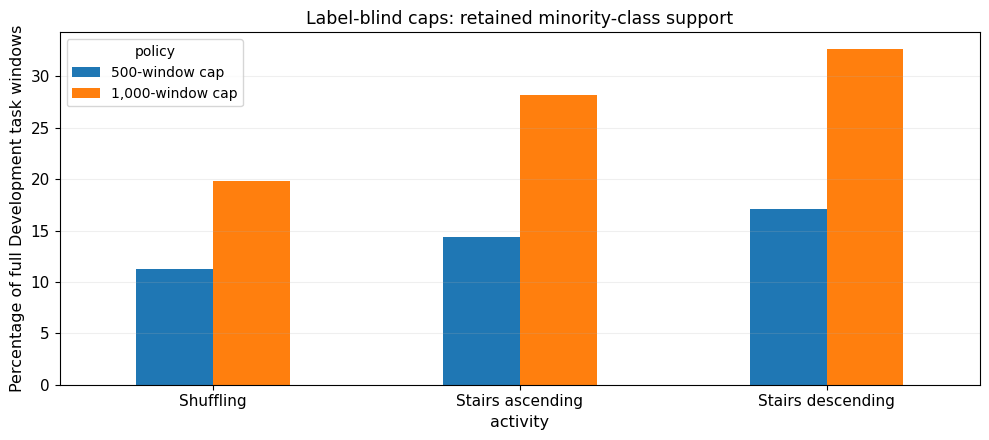

In [ ]:
# ===================== 06. Minority-Activity Evidence ========================

# ------------------- 1. Compare Label-Blind Sampling Policies ----------------
sampled = tables["sampling_policy"]
assert not sampled.duplicated(["policy", "label"]).any()
assert pd.to_numeric(sampled["windows"], errors="raise").ge(0).all()
rare_support = sampled[sampled["label"].isin([3, 4, 5])].pivot(
    index="label", columns="policy", values="windows"
).reset_index()
assert {"full", "cap_500", "cap_1000"}.issubset(rare_support.columns)
rare_support.insert(1, "activity", rare_support["label"].map(ACTIVITY_NAMES))
rare_support["retained_500_pct"] = (
    100 * rare_support["cap_500"] / rare_support["full"])
rare_support["retained_1000_pct"] = (
    100 * rare_support["cap_1000"] / rare_support["full"])
assert rare_support["full"].gt(0).all()
# Independently reconcile Stage 14 sampling counts with Stage 20 data quality.
quality_support = tables["activity_support"].set_index("activity")
assert int(quality_support["eligible_windows"].sum()) == 132397
for _, row in rare_support.iterrows():
    assert int(quality_support.loc[row["activity"], "eligible_windows"]) == int(
        row["full"]
    )
display(rare_support.round(2))
display(quality_support.loc[
    rare_support["activity"], ["eligible_windows", "supporting_subjects"]
].reset_index())

# ------------------ 2. Verify Qualified Rare-Class Support -------------------
qualified = tables["qualified_classes"]
assert len(qualified) == 16
assert set(qualified["source_code"]) == set(range(1, 9))
assert qualified.groupby("model")["support"].sum().eq(1000).all()
heldout_support = qualified[
    qualified["model"] == "1D-ResNet Weighted CE"
][["source_code", "activity", "support"]].copy()
rare_heldout = heldout_support[
    heldout_support["source_code"].isin([3, 4, 5])
].sort_values("source_code")
assert rare_heldout["support"].tolist() == [3, 10, 6]
display(rare_heldout)
print("Rare-class pooled Test support: 3 Shuffling, 10 ascending, 6 descending")

# -------------------- 3. Visualise Sampling Retention ------------------------
ax = rare_support.set_index("activity")[
    ["retained_500_pct", "retained_1000_pct"]
].rename(columns={
    "retained_500_pct": "500-window cap",
    "retained_1000_pct": "1,000-window cap",
}).plot(kind="bar", figsize=(10, 4.5), rot=0)
ax.set_ylabel("Percentage of full Development task windows")
ax.set_title("Label-blind caps: retained minority-class support")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
save_figure(ax.figure, output_dir / "final_minority_class_retention.png")
plt.show()


**07. Temperature-Scaling Evidence (Stage 19)**

Re-read the subject-disjoint calibration comparison. ECE and Brier scores decreased on average while NLL increased; this is not universal calibration improvement. Temperature scaling was **not** incorporated into the frozen final model and is not a post-hoc Test adjustment.

In [ ]:
# ==================== 07. Calibration Trade-Off Audit ========================

cal = tables["calibration"].set_index("method")
assert cal.index.is_unique
assert set(cal.index) == {"Uncalibrated", "Temperature scaled"}
calibration_audit = pd.DataFrame([
    {"metric": label,
     "uncalibrated": float(cal.loc["Uncalibrated", key]),
     "temperature_scaled": float(cal.loc["Temperature scaled", key])}
    for key, label in [
        ("ece", "ECE (10 bins)"), ("brier", "Multiclass Brier"),
        ("nll", "Negative log-likelihood"), ("accuracy", "Accuracy")
    ]
])
calibration_audit["change_scaled_minus_original"] = (
    calibration_audit["temperature_scaled"]
    - calibration_audit["uncalibrated"]
)
assert np.isfinite(calibration_audit[
    ["uncalibrated", "temperature_scaled"]
].to_numpy()).all()
assert calibration_audit.loc[
    calibration_audit["metric"] == "Negative log-likelihood",
    "change_scaled_minus_original"
].iloc[0] > 0
display(calibration_audit.round(4))
print("Stage 19 calibration: Development-only, different grouping from Stage 18.")
print("Temperature scaling used for final qualified evaluation: NO")


,metric,uncalibrated,temperature_scaled,change_scaled_minus_original
0,ECE (10 bins),0.0488,0.0286,-0.0202
1,Multiclass Brier,0.1082,0.1043,-0.0039
2,Negative log-likelihood,0.2487,0.2573,0.0086
3,Accuracy,0.9275,0.9275,0.0000


Stage 19 calibration: Development-only, different grouping from Stage 18.
Temperature scaling used for final qualified evaluation: NO


**08. Verify Stage 22–26 Evidence and Frozen Provenance**

Read the complete Stage 26 report provenance JSON and recompute **actual byte-level SHA256 hashes** for all seven source CSVs and the two approved/pending protocol records. Check the 36-job robustness grid, predeclared model names, original Test support and source identification. This verifies file alignment; it does **not** validate new data, refit a model or prove independence.

In [ ]:
# ================= 08. Check Report and Protocol Lineage =====================

# ---------------- 1. Verify Saved Stage 26 Input Digests ----------------------
report_path = output_dir / "26_report_provenance.json"
pending_path = evidence_dir / "stage_25_protocol_proposal_reconciled.json"
approved_path = evidence_dir / "stage_25_protocol_approved_qualified_test.json"
for path in (report_path, pending_path, approved_path):
    if not path.is_file():
        raise FileNotFoundError("Missing versioned provenance record: " + str(path))
report = json.loads(report_path.read_text(encoding="utf-8"))
pending = json.loads(pending_path.read_text(encoding="utf-8"))
approved = json.loads(approved_path.read_text(encoding="utf-8"))
assert pending["status"] == "PENDING_USER_REVIEW"
assert approved["status"] == "APPROVED" and approved.get("approval_record")
assert {k: v for k, v in approved.items() if k not in ("status", "approval_record")} == {
    k: v for k, v in pending.items() if k != "status"
}
def sha256_file(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

stage26_inputs = {
    "benchmark": "benchmark",
    "robustness_summary": "robustness_summary",
    "robustness_folds": "robustness_folds",
    "qualified_coverage": "qualified_coverage",
    "qualified_summary": "qualified_summary",
    "qualified_subjects": "qualified_subjects",
    "qualified_classes": "qualified_classes",
}
assert set(report["input_csv_sha256"]) == set(stage26_inputs)
for recorded_name, source_name in stage26_inputs.items():
    actual = sha256_file(source_paths[source_name])
    assert report["input_csv_sha256"][recorded_name] == actual, (
        "Stage 26 CSV changed after reporting: " + recorded_name)
assert report["pending_manifest_sha256"] == sha256_file(pending_path)
assert report["approved_manifest_sha256"] == sha256_file(approved_path)
assert report["development_sha256"] == approved["source_development_sha256"]
assert report["source_revision"] == approved["source"]["revision"]

# ---------------- 2. Verify Stage 22/23 Development Evidence -----------------
benchmark = tables["benchmark"]
assert len(benchmark) == 7 and benchmark["model"].is_unique
assert set(benchmark["model"]) == {
    "1D-ResNet", "TCN", "Random Forest", "Time-Series Transformer",
    "Multi-Scale CNN", "Weighted CNN", "Standard CNN"}
folds = tables["robustness_folds"]
assert len(folds) == 36 and not folds.duplicated(
    ["architecture", "loss_method", "seed", "fold"]).any()
assert set(folds["seed"]) == {42, 123, 2026}
assert set(folds["fold"]) == {1, 2, 3}
assert len(tables["robustness_summary"]) == 4
conditions = {
    ("1D-ResNet", "weighted_ce"), ("TCN", "weighted_ce"),
    ("1D-ResNet", "focal"), ("1D-ResNet", "class_balanced"),
}
assert set(zip(folds["architecture"], folds["loss_method"])) == conditions
expected_pairs = {(seed, fold) for seed in (42, 123, 2026)
                  for fold in (1, 2, 3)}
for _, group in folds.groupby(["architecture", "loss_method"]):
    assert set(zip(group["seed"], group["fold"])) == expected_pairs
summary = tables["robustness_summary"]
assert set(zip(summary["architecture"], summary["loss_method"])) == conditions

# ------------------- 3. Verify Frozen Qualified Results ----------------------
coverage = tables["qualified_coverage"]
assert coverage["subject_id"].tolist() == ["S023", "S032"]
assert coverage["sampled_windows"].tolist() == [500, 500]
test = tables["qualified_summary"]
assert test["model"].tolist() == [
    "1D-ResNet Weighted CE", "Random Forest"]
assert len(tables["qualified_subjects"]) == 4
assert approved["source"]["development_participants"] == 29
assert approved["source"]["expected_development_windows"] == 14201
assert approved["evaluation"]["use_test_for_tuning"] is False
assert approved["primary_model"]["architecture"] == "1D-ResNet"
assert approved["primary_model"]["optimizer_steps"] == 400
assert approved["reference_model"]["n_estimators"] == 120

final_snapshot = test[["model", "fixed_eight_class_macro_f1",
                        "accuracy"]].copy()
display(final_snapshot.round(4))
display(tables["report_selection"])
print("Stage 26 source CSV and manifest SHA256: VERIFIED AGAINST SAVED RECORD")
print("Qualified held-out results: READ ONLY; no new inference.")


,model,fixed_eight_class_macro_f1,accuracy
0,1D-ResNet Weighted CE,0.7182,0.902
1,Random Forest,0.6817,0.927


,Role,Model,Selection basis
0,Preselected primary,1D-ResNet Weighted CE,Development Stage 22/24
1,Predeclared reference,Random Forest,Development Stage 22/24


Stage 26 source CSV and manifest SHA256: VERIFIED AGAINST SAVED RECORD
Qualified held-out results: READ ONLY; no new inference.


**09. Scientific Boundaries and Final Handover**

Distinguish completed experiments from evidence still needed for broader claims. The project can be marked *completed as a research portfolio study* without claiming unseen-cohort generalisation, independent replication or a clinically deployable classifier. Do not modify the historical approval records to reflect current notebook numbering.

In [ ]:
# ================== 09. Research Closure and Limitation Audit ================

limitations = pd.DataFrame([
    {"status": "Completed", "topic": "Development design",
     "evidence": "29 people, participant-disjoint grouped validation"},
    {"status": "Completed", "topic": "Model selection",
     "evidence": "Stage 22 seven models; Stage 23 seeds and loss comparisons"},
    {"status": "Completed", "topic": "Frozen final assessment",
     "evidence": "One approved qualified same-study held-out assessment in Stage 25"},
    {"status": "Completed", "topic": "Reproducible report",
     "evidence": "Stage 26 CSV/JSON-based synthesis; SHA256 verified in this audit"},
    {"status": "Limitation", "topic": "Held-out cohort",
     "evidence": "Only S023/S032; previously inspected, not blind external Test"},
    {"status": "Limitation", "topic": "Window dependence",
     "evidence": "50% window overlap; 1,000 windows are not independent cases"},
    {"status": "Limitation", "topic": "Minority activity support",
     "evidence": "Shuffling=3; stairs ascending=10; stairs descending=6"},
    {"status": "Limitation", "topic": "Model probability estimates",
     "evidence": "Development calibration had mixed metrics; not used in final model"},
    {"status": "Future validation", "topic": "Generalisation",
     "evidence": "New participants, genuinely independent sources and broader class support"},
    {"status": "Future validation", "topic": "Reproducibility",
     "evidence": "Independent replication and separately archived trusted model artefacts"},
    {"status": "Not claimed", "topic": "Clinical deployment",
     "evidence": "No prospective, clinical or population-wide validation"},
])
display(limitations)
print("Project status: completed experimental portfolio, with stated limits.")
print("New Test authorisation or external validity established: NO")


,status,topic,evidence
0,Completed,Development design,"29 people, participant-disjoint grouped valida..."
1,Completed,Model selection,Stage 22 seven models; Stage 23 seeds and loss...
2,Completed,Frozen final assessment,One approved qualified same-study held-out ass...
3,Completed,Reproducible report,Stage 26 CSV/JSON-based synthesis; SHA256 veri...
4,Limitation,Held-out cohort,"Only S023/S032; previously inspected, not blin..."
5,Limitation,Window dependence,"50% window overlap; 1,000 windows are not inde..."
6,Limitation,Minority activity support,Shuffling=3; stairs ascending=10; stairs desce...
7,Limitation,Model probability estimates,Development calibration had mixed metrics; not...
8,Future validation,Generalisation,"New participants, genuinely independent source..."
9,Future validation,Reproducibility,Independent replication and separately archive...


Project status: completed experimental portfolio, with stated limits.
New Test authorisation or external validity established: NO


**10. Final Audit Quality Gate and Exports**

Save a compact cross-stage inventory, cohort reconciliation, protocol comparison, legacy model scores, rare-class retention, calibration contrasts, final held-out snapshot and research limitations. The provenance JSON records exact source digests and links to the Stage 26 report. A PASS means these **committed files and invariants were checked during this execution**; it does not establish an independent rerun of Stages 01–26.

In [ ]:
# ================ 10. Final Evidence Audit and Project Closure ==============

# --------------------- 1. Final Scientific Invariants ------------------------
assert set(source_inventory["source"]) == set(required_sources)
assert cohort_audit["participants"].eq(29).all()
assert cohort_audit["windows"].tolist() == [132397, 14201, 28201]
assert early_results["mean_macro_f1"].between(0, 1).all()
assert rare_support["full"].gt(0).all()
assert rare_support["cap_500"].le(rare_support["full"]).all()
assert rare_support["cap_1000"].le(rare_support["full"]).all()
assert len(calibration_audit) == 4
assert len(final_snapshot) == 2 and len(limitations) >= 10
assert report["input_csv_sha256"]["qualified_summary"] == sha256_file(
    source_paths["qualified_summary"])

# ------------------ 2. Export Newly Derived Audit Evidence ------------------
outputs = {
    "final_source_inventory.csv": source_inventory,
    "final_development_cohort_audit.csv": cohort_audit,
    "final_protocol_comparability.csv": comparison_map,
    "final_earlier_development_comparisons.csv": early_results,
    "final_minority_sampling_audit.csv": rare_support,
    "final_temperature_scaling_audit.csv": calibration_audit,
    "final_qualified_results_snapshot.csv": final_snapshot,
    "final_research_closure_and_limitations.csv": limitations,
}
for filename, frame in outputs.items():
    frame.to_csv(output_dir / filename, index=False)
audit_record = {
    "schema": "harth-final-cross-stage-audit-v1",
    "scope": "source-file verification and research closure; no model execution",
    "source_dataset": "HARTH v2.0",
    "source_revision": approved["source"]["revision"],
    "source_csv_sha256": {
        name: sha256_file(path) for name, path in source_paths.items()
    },
    "stage26_report_sha256": sha256_file(report_path),
    "approved_protocol_sha256": sha256_file(approved_path),
    "reconciled_protocol_sha256": sha256_file(pending_path),
    "development_subjects": 29,
    "qualified_test_subjects": ["S023", "S032"],
    "test_data_read_by_this_notebook": False,
    "retraining_or_test_rescoring": False,
    "external_validation_established": False,
}
(output_dir / "final_research_audit_provenance.json").write_text(
    json.dumps(audit_record, indent=2) + "\n", encoding="utf-8")
assert all((output_dir / filename).is_file() for filename in outputs)
assert (output_dir / "final_research_audit_provenance.json").is_file()
assert (output_dir / "final_minority_class_retention.png").is_file()

# --------------------- 3. Reproducibility Gate -------------------------------
# -------------------- 4. Package Only Final Audit Exports -------------------
# The shared numbered-stage downloader accepts 01–99 only. Build the FINAL
# archive separately without modifying the shared helper or earlier outputs.
from zipfile import ZIP_DEFLATED, ZipFile

final_files = sorted(
    path for path in output_dir.glob("final_*")
    if path.is_file() and not path.is_symlink()
)
expected_final_files = set(outputs) | {
    "final_research_audit_provenance.json", "final_minority_class_retention.png"
}
assert expected_final_files.issubset({path.name for path in final_files})
archive_dir = Path("/content") if Path("/content").is_dir() else root.parent
archive_path = archive_dir / "wearable_activity_recognition_Final_Audit_Outputs.zip"
with ZipFile(archive_path, mode="w", compression=ZIP_DEFLATED) as archive:
    for path in final_files:
        archive.write(path, arcname=path.name)
print("Final audit files packaged:", len(final_files))
print("Final audit ZIP:", archive_path)
print("GitHub Commit/Push performed: NO")

# -------------------------- 5. Final Quality Gate ---------------------------
print("=" * 76)
print("FINAL HARTH | CROSS-STAGE EVIDENCE AUDIT: PASSED")
print("=" * 76)
print("Development cohort and source-window accounting: VERIFIED")
print("Stage 09/13/16/17 comparisons: SOURCE-LABELLED")
print("Stage 14/20 rare-activity availability: AUDITED")
print("Stage 19 calibration trade-offs: REVIEWED")
print("Stages 22–25 source outputs and approved protocol: VERIFIED")
print("Stage 26 report CSV/manifest SHA256 lineage: MATCHED")
print("Raw data access / new training / Test inference: NONE")
print("Blind external validation or clinical readiness: NOT CLAIMED")
print("Research portfolio record: READY FOR DOCUMENTED HANDOVER")
print("Audit tables and provenance saved to:", output_dir)


Final audit files packaged: 10
Final audit ZIP: /content/wearable_activity_recognition_Final_Audit_Outputs.zip
GitHub Commit/Push performed: NO
FINAL HARTH | CROSS-STAGE EVIDENCE AUDIT: PASSED
Development cohort and source-window accounting: VERIFIED
Stage 09/13/16/17 comparisons: SOURCE-LABELLED
Stage 14/20 rare-activity availability: AUDITED
Stage 19 calibration trade-offs: REVIEWED
Stages 22–25 source outputs and approved protocol: VERIFIED
Stage 26 report CSV/manifest SHA256 lineage: MATCHED
Raw data access / new training / Test inference: NONE
Blind external validation or clinical readiness: NOT CLAIMED
Research portfolio record: READY FOR DOCUMENTED HANDOVER
Audit tables and provenance saved to: /content/human-movement-intelligence/wearable_activity_recognition/output
